# EX4 Exploratory Data Analysis

## Part 0: 
    
The following Git repository is for the COVID-19 visual dashboard operated by the Johns Hopkins University Center for Systems Science and Engineering: 

https://github.com/CSSEGISandData/COVID-19

- Read the information on the dashboard and check the datasets details

- Datasets are located in a folder: csse_covid_19_data

We will walk through the code and see how Python Pandas functions are used to process the data. 


##### The example below is COVID19 cases in the US. 

- We download two files but they seem the same. Let's use the file for confirmed cases. 

In [4]:
# Download the data from the Web

import os
import urllib.request

datapath = os.path.join("csse_covid_19_data", "csse_covid_19_data", "")

DOWNLOAD_ROOT = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
    "csse_covid_19_data/csse_covid_19_time_series/"
)

os.makedirs(datapath, exist_ok=True)

for filename in (
    "time_series_covid19_confirmed_US.csv",
    "time_series_covid19_deaths_US.csv"
):
    print("Downloading", filename)
    
    url = DOWNLOAD_ROOT + filename
    
    urllib.request.urlretrieve(
        url,
        os.path.join(datapath, filename)
    )

In [5]:
# import necessary packages and modules

import pandas as pd
import matplotlib.pyplot as plt

### Read data

In [6]:
# read data
df = pd.read_csv(datapath + "time_series_covid19_confirmed_US.csv")
df.head()

,UID,iso2,iso3,code3,FIPS,Admin2,Province_State,Country_Region,Lat,Long_,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,84001001,US,USA,840,1001.0,Autauga,Alabama,US,32.539527,-86.644082,...,19732,19759,19759,19759,19759,19759,19759,19759,19790,19790
1,84001003,US,USA,840,1003.0,Baldwin,Alabama,US,30.727750,-87.722071,...,69641,69767,69767,69767,69767,69767,69767,69767,69860,69860
2,84001005,US,USA,840,1005.0,Barbour,Alabama,US,31.868263,-85.387129,...,7451,7474,7474,7474,7474,7474,7474,7474,7485,7485
3,84001007,US,USA,840,1007.0,Bibb,Alabama,US,32.996421,-87.125115,...,8067,8087,8087,8087,8087,8087,8087,8087,8091,8091
4,84001009,US,USA,840,1009.0,Blount,Alabama,US,33.982109,-86.567906,...,18616,18673,18673,18673,18673,18673,18673,18673,18704,18704


#### We select data for two states, Washington and Texas

- If you want to select different states, modify this cell and rerun it. 

In [7]:
# Select the data for Washington and Texas
st1 = df.loc[df["Province_State"] == "Washington"]
st2 = df.loc[df["Province_State"] == "Texas"]

# drop not-used columns 
drop_cols = ['UID', 'iso2', 'iso3', 'FIPS', 'Province_State', 'Country_Region', 
             'Lat', 'Long_', 'code3', 'Combined_Key', 'Admin2']

st1 = st1.drop(columns=drop_cols)
st2 = st2.drop(columns=drop_cols)

print(st1.head())
print(st2.head())

st1.columns

      1/22/20  1/23/20  1/24/20  1/25/20  1/26/20  1/27/20  1/28/20  1/29/20  \
3145        0        0        0        0        0        0        0        0   
3146        0        0        0        0        0        0        0        0   
3147        0        0        0        0        0        0        0        0   
3148        0        0        0        0        0        0        0        0   
3149        0        0        0        0        0        0        0        0   

      1/30/20  1/31/20  ...  2/28/23  3/1/23  3/2/23  3/3/23  3/4/23  3/5/23  \
3145        0        0  ...     5631    5647    5647    5647    5647    5647   
3146        0        0  ...     5595    5606    5606    5606    5606    5606   
3147        0        0  ...    61953   62042   62042   62042   62042   62042   
3148        0        0  ...    24120   24171   24171   24171   24171   24171   
3149        0        0  ...    15762   15809   15809   15809   15809   15809   

      3/6/23  3/7/23  3/8/23  3/9/23  

Index(['1/22/20', '1/23/20', '1/24/20', '1/25/20', '1/26/20', '1/27/20',
       '1/28/20', '1/29/20', '1/30/20', '1/31/20',
       ...
       '2/28/23', '3/1/23', '3/2/23', '3/3/23', '3/4/23', '3/5/23', '3/6/23',
       '3/7/23', '3/8/23', '3/9/23'],
      dtype='object', length=1143)

### sum() function

- see the examples:
    
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.sum.html

In [8]:
# sum of column data of rows 
# columns and rows will be changed
# sum() function returns a Series
cases_st1 = st1.sum(axis=0)
cases_st2 = st2.sum(axis=0)

print(cases_st1.tail())
print(cases_st2.tail())

3/5/23    1928913
3/6/23    1928913
3/7/23    1928913
3/8/23    1928913
3/9/23    1928913
dtype: int64
3/5/23    8454365
3/6/23    8454724
3/7/23    8455291
3/8/23    8465925
3/9/23    8466220
dtype: int64


In [9]:
# createa a DataFrame of two states' data
dict_states = {'WA_cases': cases_st1, 'TX_cases': cases_st2}

data = pd.DataFrame(dict_states)

print(data.head())
print(data.tail())

         WA_cases  TX_cases
1/22/20         1         0
1/23/20         1         0
1/24/20         1         0
1/25/20         1         0
1/26/20         1         0
        WA_cases  TX_cases
3/5/23   1928913   8454365
3/6/23   1928913   8454724
3/7/23   1928913   8455291
3/8/23   1928913   8465925
3/9/23   1928913   8466220


In [10]:
# reset index (0, 1, 2, . . . ) --> adding number index
data.reset_index(inplace=True)

data.head()

,index,WA_cases,TX_cases
0,1/22/20,1,0
1,1/23/20,1,0
2,1/24/20,1,0
3,1/25/20,1,0
4,1/26/20,1,0


In [11]:
# add two new columns and set default values

data['WA_daily'] = 0
data['TX_daily'] = 0

data.head()

,index,WA_cases,TX_cases,WA_daily,TX_daily
0,1/22/20,1,0,0,0
1,1/23/20,1,0,0,0
2,1/24/20,1,0,0,0
3,1/25/20,1,0,0,0
4,1/26/20,1,0,0,0


In [12]:
# calculate daily cases and assign the values

for index, row in data.iterrows():
    if index==0:
        data.loc[index, 'WA_daily'] = data.loc[index, 'WA_cases'] 
        data.loc[index, 'TX_daily'] = data.loc[index, 'TX_cases'] 
    else:
        data.loc[index, 'WA_daily'] = data.loc[index, 'WA_cases'] - data.loc[index-1, 'WA_cases'] 
        data.loc[index, 'TX_daily'] = data.loc[index, 'TX_cases'] - data.loc[index-1, 'TX_cases'] 

    # data clearning (drop error values)
    if data.loc[index, 'WA_daily'] < 0:
        data.loc[index, 'WA_daily'] = 0
    if data.loc[index, 'TX_daily'] < 0:
        data.loc[index, 'TX_daily'] = 0

data.tail()

,index,WA_cases,TX_cases,WA_daily,TX_daily
1138,3/5/23,1928913,8454365,0,0
1139,3/6/23,1928913,8454724,0,359
1140,3/7/23,1928913,8455291,0,567
1141,3/8/23,1928913,8465925,0,10634
1142,3/9/23,1928913,8466220,0,295


In [13]:
# add a new column for the number of days
data['day_number'] = data.index

data.head()

,index,WA_cases,TX_cases,WA_daily,TX_daily,day_number
0,1/22/20,1,0,1,0,0
1,1/23/20,1,0,0,0,1
2,1/24/20,1,0,0,0,2
3,1/25/20,1,0,0,0,3
4,1/26/20,1,0,0,0,4


## Part 1

### Tasks

1. (Optional) Select states you are interested in from the COVID-19 data repository. The above cells contain the data for Washington and Texas. Hence if you would like to change states, you will update the above cells and rerun them. 

2. Conduct exploratory data analysis on the selected data and visualize the data. This may include the following:

(1) Descriptive statistics: mean, median and standard deviation, mininum, maximum and quatiles.

(2) Draw boxplots.

(3) Draw histograms.

(4) Draw scatter plots and calculate correlation coefficient factor r
    
    - Given an explanatory variable x (e.g., day_number), you display a response variable y (e.g., TX_cases). 


(5) Choose one tool that has not be used here and apply it on these COVID-19 data. 

In [31]:
# Select the data for Mississippi and Oregon
st3 = df.loc[df["Province_State"] == "Mississippi"]
st4 = df.loc[df["Province_State"] == "Oregon"]

# drop not-used columns
st3 = st3.drop(columns=drop_cols)
st4 = st4.drop(columns=drop_cols)

# sum the county rows into one cumulative series per state
cases_st3 = st3.sum(axis=0)
cases_st4 = st4.sum(axis=0)

dict_states2 = {'MS_cases': cases_st3, 'OR_cases': cases_st4}
data2 = pd.DataFrame(dict_states2)

data2.reset_index(inplace=True)

data2['MS_daily'] = 0
data2['OR_daily'] = 0

for index, row in data2.iterrows():
    if index == 0:
        data2.loc[index, 'MS_daily'] = data2.loc[index, 'MS_cases']
        data2.loc[index, 'OR_daily'] = data2.loc[index, 'OR_cases']
    else:
        data2.loc[index, 'MS_daily'] = data2.loc[index, 'MS_cases'] - data2.loc[index-1, 'MS_cases']
        data2.loc[index, 'OR_daily'] = data2.loc[index, 'OR_cases'] - data2.loc[index-1, 'OR_cases']

    if data2.loc[index, 'MS_daily'] < 0:
        data2.loc[index, 'MS_daily'] = 0
    if data2.loc[index, 'OR_daily'] < 0:
        data2.loc[index, 'OR_daily'] = 0

data2['day_number'] = data2.index

data2.tail()


,index,MS_cases,OR_cases,MS_daily,OR_daily,day_number
1138,3/5/23,989282,961523,0,0,1138
1139,3/6/23,989282,961523,0,0,1139
1140,3/7/23,989282,961523,0,0,1140
1141,3/8/23,990756,963564,1474,2041,1141
1142,3/9/23,990756,963564,0,0,1142


#### Task (1)


In [34]:
# descriptive statistics for MS and OR (cumulative and daily cases)
cols = ['MS_cases', 'OR_cases', 'MS_daily', 'OR_daily']

stats = data2[cols].describe()
stats.loc['median'] = data2[cols].median()

print(stats.round(2))

         MS_cases   OR_cases  MS_daily  OR_daily
count     1143.00    1143.00    1143.0   1143.00
mean    464941.58  393942.42     866.8    843.01
std     346366.89  353270.12    1807.5   1776.21
min          0.00       0.00       0.0      0.00
25%     121187.00   46219.00       0.0      0.00
50%     381147.00  238463.00     271.0    282.00
75%     806838.00  760803.00     959.5   1026.00
max     990756.00  963564.00   22456.0  28024.00
median  381147.00  238463.00     271.0    282.00


#### Task (2)

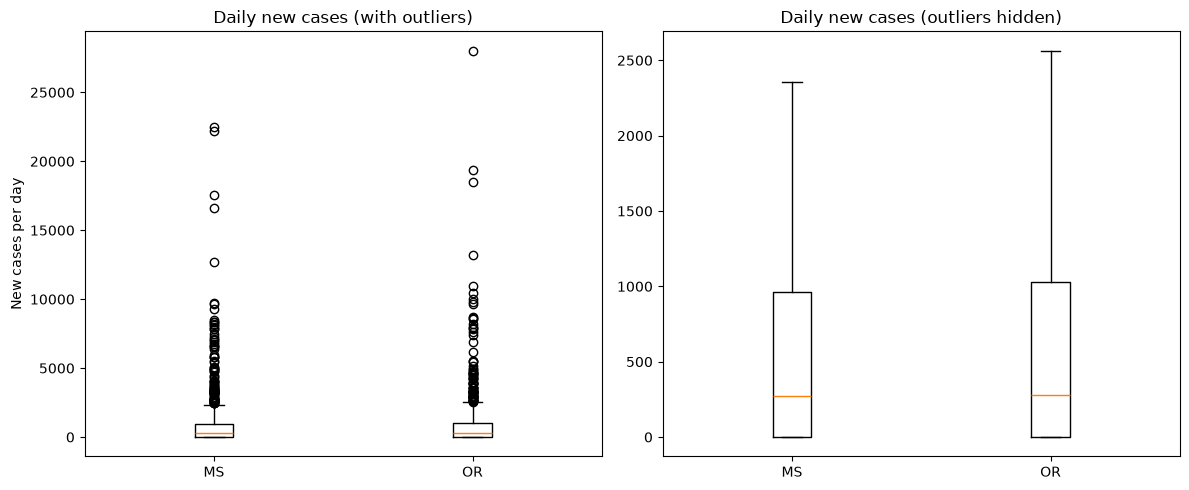

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot([data2['MS_daily'], data2['OR_daily']], tick_labels=['MS', 'OR'])
axes[0].set_title('Daily new cases (with outliers)')
axes[0].set_ylabel('New cases per day')

axes[1].boxplot([data2['MS_daily'], data2['OR_daily']], tick_labels=['MS', 'OR'], showfliers=False)
axes[1].set_title('Daily new cases (outliers hidden)')

plt.tight_layout()
plt.show()

#### Task (3)

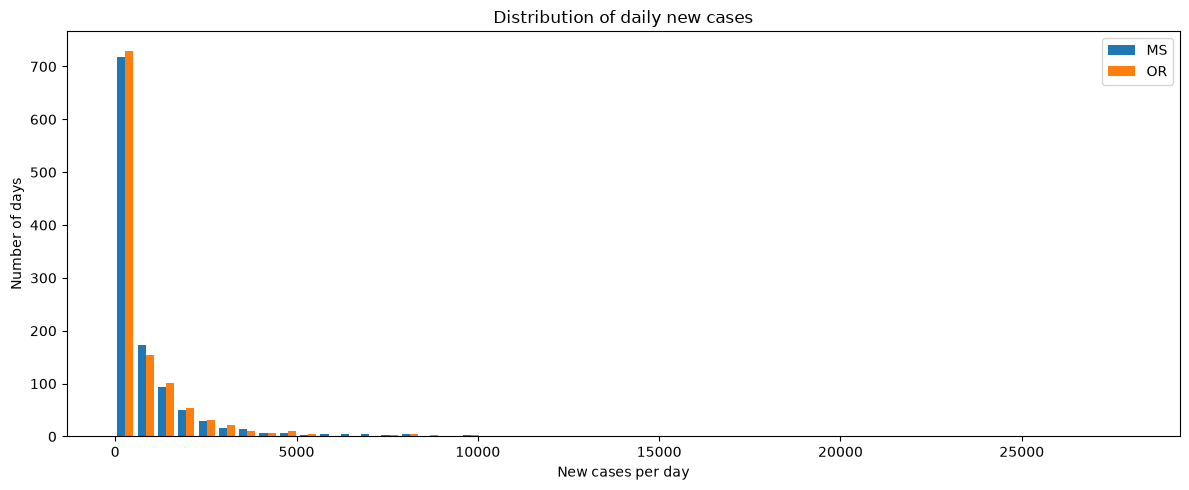

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist([data2['MS_daily'], data2['OR_daily']], bins=50, label=['MS', 'OR'])
ax.set_title('Distribution of daily new cases')
ax.set_xlabel('New cases per day')
ax.set_ylabel('Number of days')
ax.legend()

plt.tight_layout()
plt.show()

#### Task (4)

r (day_number vs MS_cases): 0.9868
r (day_number vs OR_cases): 0.9671


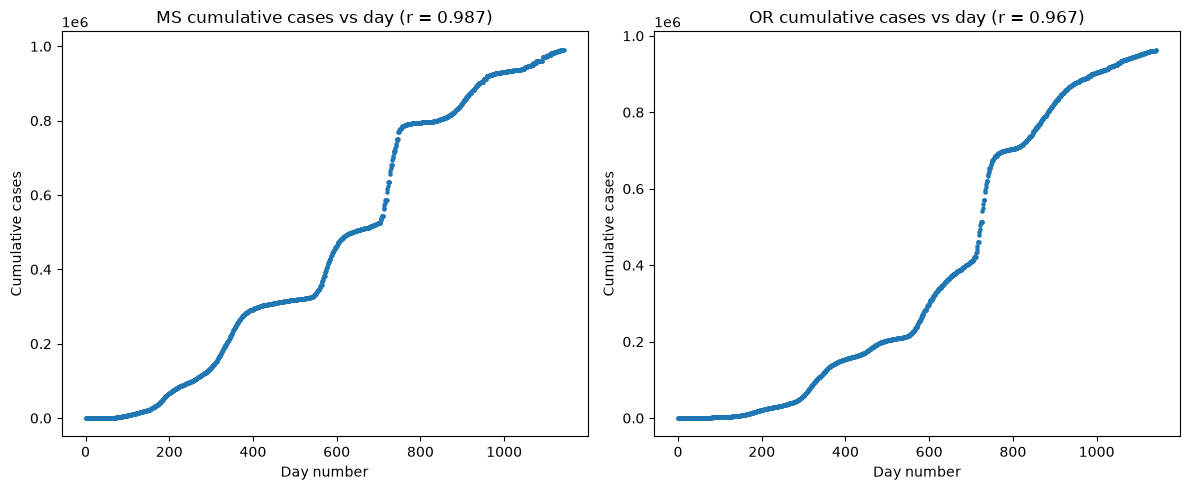

In [44]:
# correlation coefficient r between day_number and cumulative cases
r_ms = data2['day_number'].corr(data2['MS_cases'])
r_or = data2['day_number'].corr(data2['OR_cases'])

print(f"r (day_number vs MS_cases): {r_ms:.4f}")
print(f"r (day_number vs OR_cases): {r_or:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(data2['day_number'], data2['MS_cases'], s=5)
axes[0].set_title(f'MS cumulative cases vs day (r = {r_ms:.3f})')
axes[0].set_xlabel('Day number')
axes[0].set_ylabel('Cumulative cases')

axes[1].scatter(data2['day_number'], data2['OR_cases'], s=5)
axes[1].set_title(f'OR cumulative cases vs day (r = {r_or:.3f})')
axes[1].set_xlabel('Day number')
axes[1].set_ylabel('Cumulative cases')

plt.tight_layout()
plt.show()

#### Task (5)
Graphing and comparing a 7 day rolling average of cases, because cases weren't reported every single day.

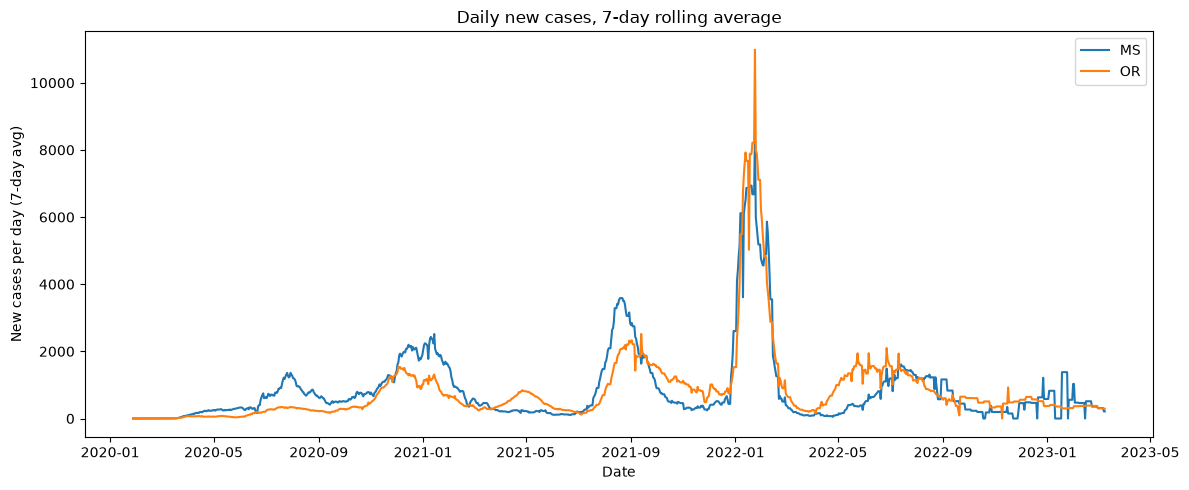

In [45]:
# convert the date strings (from reset_index) to real dates for the x-axis
data2['date'] = pd.to_datetime(data2['index'], format='%m/%d/%y')

# 7-day rolling average of daily new cases
data2['MS_7day'] = data2['MS_daily'].rolling(window=7).mean()
data2['OR_7day'] = data2['OR_daily'].rolling(window=7).mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(data2['date'], data2['MS_7day'], label='MS')
ax.plot(data2['date'], data2['OR_7day'], label='OR')
ax.set_title('Daily new cases, 7-day rolling average')
ax.set_xlabel('Date')
ax.set_ylabel('New cases per day (7-day avg)')
ax.legend()

plt.tight_layout()
plt.show()

## Part 2

Write a summary of your findings from the data analysis. 

It's clear that covid rates varied with time, so there were likely real-world events or human patterns that influenced diagnosis rates (a quick google search indicates that Fall 2021 and Winter 2022 spikes were caused by the delta and omnicron variants; respectively). Both states appear to share the same spikes, indicating that they were caused by nationwide events rather than being state-specific. 

It's also clear that Mississippi had comparitively more covid cases than Oregon, as despite having 1.2m less inhabatants, it has more total covid cases.



### Resources

#### Boxplot
https://towardsdatascience.com/understanding-boxplots-5e2df7bcbd51


- matplotlib.pyplot boxplot demo
https://matplotlib.org/3.1.1/gallery/pyplots/boxplot_demo_pyplot.html


#### matplotlib.pyplot
- scatter plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.scatter.html


- histogram plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.hist.html


#### pandas DataFrame
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html


- describe()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html


- corr()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html


- hist()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html


- plot.scatter()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.scatter.html


- pivot()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.pivot.html